# Reinforcement Learning for Asset Allocation (PPO / SAC)

Allocation is a sequential problem: today's weights set tomorrow's trading costs, and the right exposure depends on the market. Reinforcement learning promises to learn that policy directly. But twenty years of weekly data is only about a thousand observations, and a deep policy has thousands of parameters. This notebook gives the idea a fair test and asks the questions an investment committee would ask.

**What it does.** It trains PPO and SAC agents to allocate weekly across eight U.S.-listed ETFs plus cash, net of trading costs. It trains on 2008–2018, selects on 2019–2020 and tests on 2021–2026.

The agents are then compared with 1/N, 60/40, minimum variance and trend following, with a bootstrap test of the Sharpe difference.

**Data.** Daily total-return prices of SPY, EFA, EEM, TLT, IEF, LQD, GLD and DBC since 2007 (Yahoo Finance), and the 3-month T-bill, the VIX and the 10y–2y Treasury slope (FRED).

**Methods.** A custom Gymnasium environment (state: momentum, volatility, macro and current weights; action: softmax weights; reward: net log return minus a variance penalty), Stable-Baselines3 PPO and SAC with three seeds each, Ledoit–Wolf minimum variance and a stationary block bootstrap.

**Key output.** Out-of-sample return, volatility, Sharpe ratio, drawdown and turnover by strategy, seed dispersion, the agents' weight paths, how their allocation reacts to the VIX, and the probability that RL beats 1/N.

## 1. Why look at RL for allocation, and why be sceptical

A portfolio problem is sequential: today's weights determine tomorrow's trading costs, and the right exposure depends on the state of the market. Reinforcement learning optimises a **policy** that maps the state to weights directly, with costs inside the objective, instead of a forecast followed by an optimiser.

The catch is data. Twenty years of weekly returns is about a thousand observations, and a deep policy has thousands of parameters. An RL agent is a high-variance estimator in a low signal-to-noise problem. The questions an investment committee would ask are therefore:

1. Does the agent beat simple rules **out of sample**, after costs?
2. Is the result stable across **random seeds**, or is it one lucky run?
3. Does the learned policy make **economic sense** (for example, de-risking when volatility is high)?

The notebook answers all three with a strict time split: train 2008–2018, select on 2019–2020, and test once on 2021–2026, a period with the 2022 bond crash that none of the training data contains.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import gymnasium as gym
import stable_baselines3 as sb3
import yfinance as yf
from gymnasium import spaces
from sklearn.covariance import LedoitWolf
from stable_baselines3 import PPO, SAC

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

TICKERS = ["SPY", "EFA", "EEM", "TLT", "IEF", "LQD", "GLD", "DBC"]
ASSETS = TICKERS + ["Cash"]
START = "2007-05-01"
# test = everything after VALID_END
TRAIN_END, VALID_END = "2018-12-31", "2020-12-31"
# each training episode is a random two-year window
EPISODE_WEEKS = 104
COST_BP = 10  # one-way cost per unit of turnover
# reward = net log return − RISK_PENALTY/2 · return²
RISK_PENALTY = 8.0
PPO_STEPS, SAC_STEPS = 200_000, 30_000
SEEDS = [0, 1, 2]
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(
    f"stable-baselines3 {sb3.__version__} · gymnasium {gym.__version__} ·"
    f" torch {torch.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

stable-baselines3 2.9.0 · gymnasium 1.4.0 · torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


STRAT_COLORS = {
    "1/N": "#9c9b97",
    "60/40": PALETTE[3],
    "Min variance": PALETTE[0],
    "Trend following": PALETTE[2],
    "PPO": PALETTE[1],
    "SAC": PALETTE[6],
}
ASSET_COLORS = dict(zip(ASSETS, PALETTE + ["#c9c8c3"]))

## 3. Data: weekly returns and state variables

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ]
    if isinstance(px, pd.Series):
        px = px.to_frame(TICKERS[0])
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px[TICKERS].reset_index()


prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
# completed sessions only (no intraday row)
prices = prices[prices.index < pd.Timestamp.today().normalize()]
prices = prices.dropna(how="all").ffill(limit=3)

# --- Data cleaning: one-day bad prints that reverse the next day are replaced
# by interpolation
raw_ret = np.log(prices).diff()
# robust daily sigma
scale = raw_ret.abs().rolling(120, min_periods=40).median().shift() / 0.6745
spike = (raw_ret.abs() > 10 * scale) & (
    (raw_ret + raw_ret.shift(-1)).abs() < 0.25 * raw_ret.abs()
)
# A genuine crash-and-rebound (e.g. 12-13 Mar 2020) moves many assets at once;
# a bad print is idiosyncratic.
market_wide = (raw_ret.abs() > 4 * scale).sum(axis=1) >= 3
spike = (
    spike & ~market_wide.values[:, None]
    if prices.shape[1] >= 3
    else spike & False
)
for c in prices.columns[spike.any()]:
    print(
        f"Data fix · {c}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[c]])} interpolated"
    )
prices = prices.mask(spike).interpolate(limit_area="inside")
returns = np.log(prices).diff().dropna()
EVAL_DATE = returns.index.max()
print(
    f"{len(returns):,} trading days · {returns.index.min():%Y-%m-%d} →"
    f" {EVAL_DATE:%Y-%m-%d} · {', '.join(prices.columns)}"
)

4,897 trading days · 2007-05-02 → 2026-10-16 · SPY, EFA, EEM, TLT, IEF, LQD, GLD, DBC


In [4]:
# Weekly (Friday) simple returns; cash earns the 3-month T-bill
daily_simple = np.expm1(returns)
weekly = (1 + daily_simple).resample("W-FRI").prod() - 1
macro = pd.DataFrame({
    "tbill": fred.get_series("DTB3", observation_start=START),
    "vix": fred.get_series("VIXCLS", observation_start=START),
    "slope": fred.get_series("T10Y2Y", observation_start=START),
}).ffill()
macro.index = pd.to_datetime(macro.index)
macro_w = macro.resample("W-FRI").last().reindex(weekly.index).ffill()
weekly["Cash"] = macro_w["tbill"] / 100 / 52
weekly = weekly.dropna()

# --- State features, all known at the end of week t (used to choose weights
# for week t+1)
logw = np.log1p(weekly[TICKERS])
feat = {}
for h in (4, 13, 52):
    feat[f"mom{h}"] = logw.rolling(h).sum()
feat["vol13"] = logw.rolling(13).std() * np.sqrt(52)
F = pd.concat(feat, axis=1)
F[("macro", "vix")] = np.log(macro_w["vix"])
F[("macro", "slope")] = macro_w["slope"]
F[("macro", "tbill")] = macro_w["tbill"]
F = F.dropna()
weekly = weekly.loc[F.index]

# Standardise with training-period statistics only (no look-ahead)
train_mask = F.index <= TRAIN_END
mu_f, sd_f = F[train_mask].mean(), F[train_mask].std()
Z = ((F - mu_f) / sd_f).clip(-5, 5)

split = pd.Series(
    np.where(
        F.index <= TRAIN_END,
        "train",
        np.where(F.index <= VALID_END, "validation", "test"),
    ),
    index=F.index,
)
print(f"{len(weekly)} weeks · {Z.shape[1]} state features")
print(
    split.groupby(split)
    .apply(
        lambda s: (
            f"{s.index.min():%Y-%m-%d} →"
            f" {s.index.max():%Y-%m-%d} ({len(s)} weeks)"
        )
    )
    .to_string()
)
(
    weekly[ASSETS]
    .groupby(split)
    .apply(lambda r: (1 + r).prod() ** (52 / len(r)) - 1)
    * 100
).round(1).loc[["train", "validation", "test"]]

965 weeks · 35 state features
test          2021-01-01 → 2026-10-16 (303 weeks)
train         2008-04-25 → 2018-12-28 (558 weeks)
validation    2019-01-04 → 2020-12-25 (104 weeks)


,SPY,EFA,EEM,TLT,IEF,LQD,GLD,DBC,Cash
train,7.80,0.70,0.10,5.70,3.90,4.80,2.70,-8.60,0.40
validation,24.30,14.20,15.60,16.20,9.10,14.10,20.70,1.30,1.20
test,14.80,9.50,6.20,-8.00,-2.10,-1.20,14.20,18.20,3.30


The table already shows why the test period is hard: long Treasuries (TLT) returned about 4% a year in training and lost heavily in 2021–2026, while gold and commodities did the reverse. An agent that learned "bonds hedge equities" in 2008–2018 meets a regime in which they did not.

## 4. The environment

| Element | Definition |
|---|---|
| State $s_t$ | 4-, 13- and 52-week momentum and 13-week volatility of each ETF, log VIX, the 10y–2y slope, the T-bill rate (all standardised), plus the current weights |
| Action $a_t$ | 9 unbounded scores → weights $w = \mathrm{softmax}(2a)$: long-only, fully invested, cash allowed |
| Transition | weights drift with the week's returns |
| Reward | $\log(1+r^{net}_{t+1}) - \tfrac{\lambda}{2}(r^{net}_{t+1})^2$ with $r^{net} = w^\top r - c\,\lVert w - w^{drift}\rVert_1$, $\lambda = 8$, $c$ = 10 bp |

The variance penalty makes the objective a mean–variance utility, so the agent is not simply rewarded for leverage to equities. Training episodes are random two-year windows inside 2008–2018. Evaluation runs one deterministic pass through each period.

In [5]:
R_ALL = weekly[ASSETS].to_numpy()
Z_ALL = Z.to_numpy().astype(np.float32)
N_A = len(ASSETS)


class AllocationEnv(gym.Env):
    """
    Weekly allocation over 8 ETFs + cash. Indices refer to rows of Z_ALL /
    R_ALL.
    """

    def __init__(self, start, end, episode_len=None, seed=0):
        super().__init__()
        # usable rows: the state at t, the return at t+1
        self.lo, self.hi = start, end
        self.episode_len = episode_len
        self.rng = np.random.default_rng(seed)
        self.observation_space = spaces.Box(
            -10, 10, shape=(Z_ALL.shape[1] + N_A,), dtype=np.float32
        )
        self.action_space = spaces.Box(-1, 1, shape=(N_A,), dtype=np.float32)

    def _obs(self):
        return np.concatenate([Z_ALL[self.t], self.w.astype(np.float32)])

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if self.episode_len:
            self.t = int(
                self.rng.integers(self.lo, self.hi - self.episode_len)
            )
            self.stop = self.t + self.episode_len
        else:
            self.t, self.stop = self.lo, self.hi
        self.w = np.full(N_A, 1 / N_A)
        return self._obs(), {}

    def step(self, action):
        target = np.exp(2 * action - np.max(2 * action))
        target /= target.sum()
        cost = COST_BP / 1e4 * np.abs(target - self.w).sum()
        r = R_ALL[self.t + 1]
        gross = target @ r
        net = gross - cost
        # scaled for the optimiser
        reward = float(np.log1p(net) - 0.5 * RISK_PENALTY * net**2) * 100
        turnover = np.abs(target - self.w).sum()
        self.w = target * (1 + r) / (1 + gross)
        self.t += 1
        done = self.t >= self.stop
        return (
            self._obs(),
            reward,
            done,
            False,
            {"net": net, "turnover": turnover, "weights": target},
        )


idx = np.arange(len(Z))
i_train_end = (
    int(np.searchsorted(Z.index, pd.Timestamp(TRAIN_END), side="right")) - 1
)
i_valid_end = (
    int(np.searchsorted(Z.index, pd.Timestamp(VALID_END), side="right")) - 1
)
PERIODS = {
    "train": (0, i_train_end),
    "validation": (i_train_end, i_valid_end),
    "test": (i_valid_end, len(Z) - 1),
}

# Quick sanity check: a random policy runs end-to-end
env = AllocationEnv(*PERIODS["train"], episode_len=EPISODE_WEEKS)
obs, _ = env.reset()
total = 0
for _ in range(EPISODE_WEEKS):
    obs, rwd, done, _, info = env.step(env.action_space.sample())
    total += rwd
print(
    f"observation size {obs.shape[0]} · random-policy episode reward"
    f" {total:.1f}"
)

observation size 44 · random-policy episode reward -3.9


## 5. Benchmarks

The agents have to beat rules that need no training:

- **1/N** across the eight ETFs and cash, rebalanced weekly;
- **60/40**: 60% SPY, 40% IEF;
- **Minimum variance**: Ledoit–Wolf covariance on the trailing 156 weeks, long-only, 35% cap;
- **Trend following**: equal weight in every ETF whose 52-week return is positive, the rest in cash (a classic time-series momentum rule).

All of them pay the same 10 bp per unit of turnover.

In [6]:
from scipy.optimize import minimize


def min_var_weights(t):
    # not enough history yet: start from equal weights
    if t < 52:
        return np.append(np.full(len(TICKERS), 1 / len(TICKERS)), 0.0)
    hist = R_ALL[max(0, t - 155) : t + 1, : len(TICKERS)]
    S = LedoitWolf().fit(hist).covariance_
    n = len(TICKERS)
    res = minimize(
        lambda w: w @ S @ w,
        np.full(n, 1 / n),
        method="SLSQP",
        bounds=[(0, 0.35)] * n,
        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
    )
    return np.append(res.x, 0.0)


def rule_weights(name, t):
    if name == "1/N":
        return np.full(N_A, 1 / N_A)
    if name == "60/40":
        w = np.zeros(N_A)
        w[ASSETS.index("SPY")], w[ASSETS.index("IEF")] = 0.6, 0.4
        return w
    if name == "Min variance":
        return min_var_weights(t)
    if name == "Trend following":
        pos = (
            F.iloc[t][[("mom52", c) for c in TICKERS]].to_numpy() > 0
        ).astype(float)
        w = np.append(pos / len(TICKERS), 0.0)
        w[-1] = 1 - w.sum()
        return w
    raise KeyError(name)


def run_policy(choose, period):
    """
    Walk through one period; `choose(t, obs)` returns target weights. Returns
    net returns, turnover, weights.
    """
    lo, hi = PERIODS[period]
    w = np.full(N_A, 1 / N_A)
    nets, turns, ws = [], [], []
    for t in range(lo, hi):
        obs = np.concatenate([Z_ALL[t], w.astype(np.float32)])
        target = choose(t, obs)
        turn = np.abs(target - w).sum()
        r = R_ALL[t + 1]
        gross = target @ r
        nets.append(gross - COST_BP / 1e4 * turn)
        turns.append(turn)
        ws.append(target)
        w = target * (1 + r) / (1 + gross)
    dates = Z.index[lo + 1 : hi + 1]
    return (
        pd.Series(nets, index=dates),
        np.array(turns),
        pd.DataFrame(ws, index=dates, columns=ASSETS),
    )


def perf_stats(r, turns):
    wealth = (1 + r).cumprod()
    years = len(r) / 52
    rf = weekly.loc[r.index, "Cash"]
    return {
        "ann. return %": (wealth.iloc[-1] ** (1 / years) - 1) * 100,
        "ann. vol %": r.std() * np.sqrt(52) * 100,
        "Sharpe": (r - rf).mean() / r.std() * np.sqrt(52),
        "max drawdown %": (wealth / wealth.cummax() - 1).min() * 100,
        "weekly CVaR95 %": -r[r <= r.quantile(0.05)].mean() * 100,
        "annual turnover ×": turns.sum() / years,
    }


RULES = ["1/N", "60/40", "Min variance", "Trend following"]
bench = {
    (n, p): run_policy(lambda t, o, n=n: rule_weights(n, t), p)
    for n in RULES
    for p in PERIODS
}
pd.DataFrame({
    (n, p): perf_stats(*bench[(n, p)][:2])
    for n in RULES
    for p in ("validation", "test")
}).T.round(2)

ann. return %  ann. vol %  Sharpe  max drawdown %  \
1/N             validation          13.70       11.43    1.08          -15.41   
                test                 6.46        7.72    0.42          -16.98   
60/40           validation          18.84       13.66    1.25          -18.34   
                test                 7.99       10.16    0.48          -20.80   
Min variance    validation          15.25       12.85    1.08          -17.24   
                test                 6.81        8.68    0.42          -19.05   
Trend following validation           8.00        7.05    0.96           -8.25   
                test                 6.63        6.35    0.53           -6.59   

                            weekly CVaR95 %  annual turnover ×  
1/N             validation             3.83               0.68  
                test                   2.15               0.61  
60/40           validation             4.62               1.40  
                test                   2.82               0.69  
Min variance    validation             4.30               0.82  
                test                   2.43               0.67  
Trend following validation             2.43               5.67  
                test                   1.92               4.97

## 6. Training PPO and SAC

**PPO** (Schulman et al., 2017) is an on-policy actor–critic with a clipped objective that keeps each update close to the previous policy; it is the robust default. **SAC** (Haarnoja et al., 2018) is off-policy and maximises reward plus policy entropy, which keeps exploring and reuses past experience, so it needs far fewer environment steps.

Both use two hidden layers of 64 units. Three seeds per algorithm show how much of any result is luck. The seed with the best **validation** Sharpe is the one a desk would deploy, so it is reported separately from the seed average.

In [7]:
def agent_choose(model):
    def choose(t, obs):
        a, _ = model.predict(obs, deterministic=True)
        e = np.exp(2 * a - np.max(2 * a))
        return e / e.sum()

    return choose


agents, agent_runs, train_log = {}, {}, []
t0 = time.perf_counter()
for seed in SEEDS:
    env = AllocationEnv(
        *PERIODS["train"], episode_len=EPISODE_WEEKS, seed=seed
    )
    model = PPO(
        "MlpPolicy",
        env,
        n_steps=2048,
        batch_size=256,
        learning_rate=3e-4,
        gamma=0.97,
        ent_coef=0.001,
        policy_kwargs=dict(net_arch=[64, 64]),
        seed=seed,
        verbose=0,
    )
    model.learn(PPO_STEPS)
    agents[("PPO", seed)] = model
    for p in PERIODS:
        agent_runs[("PPO", seed, p)] = run_policy(agent_choose(model), p)
print(
    f"PPO: {len(SEEDS)} seeds × {PPO_STEPS:,} steps in"
    f" {time.perf_counter() - t0:.0f}s"
)

t0 = time.perf_counter()
for seed in SEEDS:
    env = AllocationEnv(
        *PERIODS["train"], episode_len=EPISODE_WEEKS, seed=seed
    )
    model = SAC(
        "MlpPolicy",
        env,
        learning_rate=3e-4,
        buffer_size=SAC_STEPS,
        batch_size=256,
        gamma=0.97,
        train_freq=2,
        gradient_steps=1,
        learning_starts=2_000,
        policy_kwargs=dict(net_arch=[64, 64]),
        seed=seed,
        verbose=0,
    )
    model.learn(SAC_STEPS)
    agents[("SAC", seed)] = model
    for p in PERIODS:
        agent_runs[("SAC", seed, p)] = run_policy(agent_choose(model), p)
print(
    f"SAC: {len(SEEDS)} seeds × {SAC_STEPS:,} steps in"
    f" {time.perf_counter() - t0:.0f}s"
)

seed_table = pd.DataFrame({
    (algo, seed, p): perf_stats(*agent_runs[(algo, seed, p)][:2])
    for algo in ("PPO", "SAC")
    for seed in SEEDS
    for p in PERIODS
}).T
seed_table.index.names = ["algo", "seed", "period"]
seed_table[[
    "ann. return %",
    "ann. vol %",
    "Sharpe",
    "max drawdown %",
    "annual turnover ×",
]].unstack("period").round(2)

PPO: 3 seeds × 200,000 steps in 313s


SAC: 3 seeds × 30,000 steps in 314s


ann. return %                  ann. vol %                  Sharpe  \
period             test train validation       test train validation   test   
algo seed                                                                     
PPO  0             7.90 46.36      13.44       8.24 11.47      18.27   0.57   
     1             8.10 46.06       8.24       9.44 11.91      19.07   0.52   
     2             9.14 43.88      11.01       9.71 11.44      18.85   0.61   
SAC  0             2.20 19.23       8.62       8.03  8.95      16.63  -0.10   
     1             8.86 17.50       9.00      10.44  9.97      15.71   0.55   
     2             5.47 18.87       6.66       8.57  8.77      18.40   0.28   

                           max drawdown %                   annual turnover ×  \
period    train validation           test  train validation              test   
algo seed                                                                       
PPO  0     3.35       0.72         -16.19 -10.74     -28.51             19.10   
     1     3.21       0.45         -18.78 -12.19     -29.60             17.91   
     2     3.21       0.59         -18.22 -11.69     -30.38             17.60   
SAC  0     1.97       0.51         -19.91  -8.93     -28.46             18.51   
     1     1.63       0.55         -18.49 -24.62     -25.29             20.18   
     2     1.97       0.38         -13.84 -13.74     -29.87             16.24   

                            
period    train validation  
algo seed                   
PPO  0    27.70      20.89  
     1    25.94      17.27  
     2    26.58      17.77  
SAC  0    21.56      18.03  
     1    25.88      21.18  
     2    25.14      16.57

## 7. Out-of-sample scoreboard (2021–2026)

In [8]:
best_seed = {
    algo: seed_table.xs((algo, "validation"), level=["algo", "period"])[
        "Sharpe"
    ].idxmax()
    for algo in ("PPO", "SAC")
}
rows = {n: perf_stats(*bench[(n, "test")][:2]) for n in RULES}
for algo in ("PPO", "SAC"):
    rows[f"{algo} (best validation seed {best_seed[algo]})"] = perf_stats(
        *agent_runs[(algo, best_seed[algo], "test")][:2]
    )
    avg = seed_table.xs((algo, "test"), level=["algo", "period"]).mean()
    rows[f"{algo} (average of {len(SEEDS)} seeds)"] = avg.to_dict()
scoreboard = pd.DataFrame(rows).T


# Stationary block bootstrap (Politis–Romano) of the Sharpe difference vs 1/N
# on the test period
def block_bootstrap_idx(n, mean_block=8, n_boot=5_000, seed=7):
    rng = np.random.default_rng(seed)
    out = np.empty((n_boot, n), dtype=int)
    for b in range(n_boot):
        i, pos = rng.integers(n), 0
        while pos < n:
            out[b, pos] = i
            pos += 1
            i = (
                rng.integers(n)
                if rng.random() < 1 / mean_block
                else (i + 1) % n
            )
    return out


ref = bench[("1/N", "test")][0]
rf_test = weekly.loc[ref.index, "Cash"].to_numpy()
B = block_bootstrap_idx(len(ref))


def sharpe_rows(x):
    ex = x - rf_test[B]
    return ex.mean(axis=1) / x.std(axis=1) * np.sqrt(52)


p_beat = {}
for name in scoreboard.index:
    if name == "1/N" or "average" in name:
        continue
    series = (
        bench[(name, "test")][0]
        if name in RULES
        else agent_runs[(name.split()[0], best_seed[name.split()[0]], "test")][
            0
        ]
    )
    diff = sharpe_rows(series.to_numpy()[B]) - sharpe_rows(ref.to_numpy()[B])
    p_beat[name] = (diff > 0).mean()
scoreboard["P(Sharpe > 1/N)"] = pd.Series(p_beat)
scoreboard.round(2)

,ann. return %,ann. vol %,Sharpe,max drawdown %,weekly CVaR95 %,annual turnover ×,P(Sharpe > 1/N)
1/N,6.46,7.72,0.42,-16.98,2.15,0.61,NaN
60/40,7.99,10.16,0.48,-20.80,2.82,0.69,0.62
Min variance,6.81,8.68,0.42,-19.05,2.43,0.67,0.77
Trend following,6.63,6.35,0.53,-6.59,1.92,4.97,0.63
PPO (best validation seed 0),7.90,8.24,0.57,-16.19,2.29,19.10,0.70
PPO (average of 3 seeds),8.38,9.13,0.57,-17.73,2.45,18.20,NaN
SAC (best validation seed 1),8.86,10.44,0.55,-18.49,2.85,20.18,0.72
SAC (average of 3 seeds),5.51,9.02,0.24,-17.41,2.51,18.31,NaN


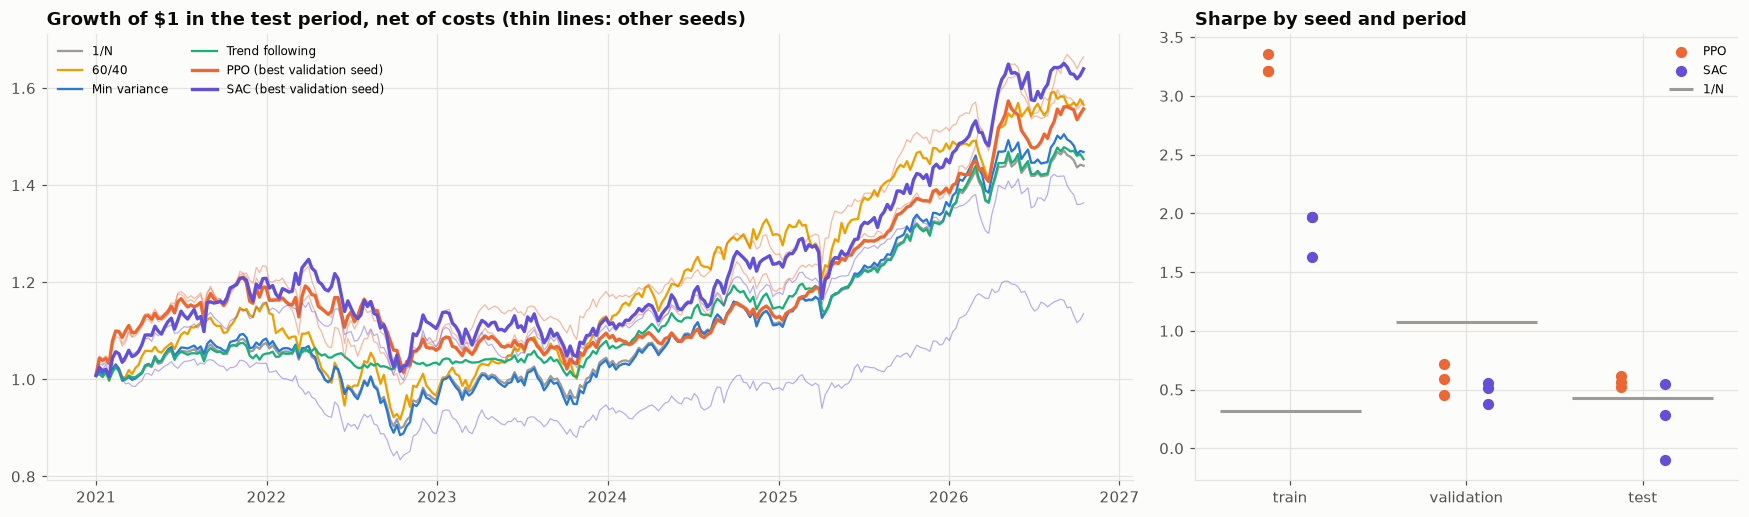

In [9]:
# --- Chart 1: test-period wealth, and seed dispersion
fig, axes = plt.subplots(
    1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2, 1]}
)
ax = axes[0]
for n in RULES:
    r = bench[(n, "test")][0]
    ax.plot(r.index, (1 + r).cumprod(), color=STRAT_COLORS[n], lw=1.5, label=n)
for algo in ("PPO", "SAC"):
    for seed in SEEDS:
        r = agent_runs[(algo, seed, "test")][0]
        best = seed == best_seed[algo]
        ax.plot(
            r.index,
            (1 + r).cumprod(),
            color=STRAT_COLORS[algo],
            lw=2.2 if best else 0.8,
            alpha=1 if best else 0.45,
            label=f"{algo} (best validation seed)" if best else None,
        )
ax.set_title(
    "Growth of $1 in the test period, net of costs (thin lines: other seeds)"
)
ax.legend(fontsize=8, ncol=2)
ax = axes[1]
for k, algo in enumerate(("PPO", "SAC")):
    for j, p in enumerate(PERIODS):
        vals = seed_table.xs((algo, p), level=["algo", "period"])["Sharpe"]
        ax.scatter(
            np.full(len(vals), j + (k - 0.5) * 0.25),
            vals,
            color=STRAT_COLORS[algo],
            s=40,
            label=algo if j == 0 else None,
        )
for j, p in enumerate(PERIODS):
    ax.hlines(
        perf_stats(*bench[("1/N", p)][:2])["Sharpe"],
        j - 0.4,
        j + 0.4,
        color=STRAT_COLORS["1/N"],
        lw=2,
        label="1/N" if j == 0 else None,
    )
ax.set_xticks(range(3), list(PERIODS))
ax.set_title("Sharpe by seed and period")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_test_wealth_and_seeds")
plt.show()

## 8. What did the agents learn?

Two checks: the weights each agent actually held through the test period, and a **policy response curve**. The response curve takes every test-period state, sets the VIX feature to a chosen level and keeps everything else unchanged, then averages the agent's weights. A sensible policy should move from risky assets toward bonds and cash as the VIX rises.

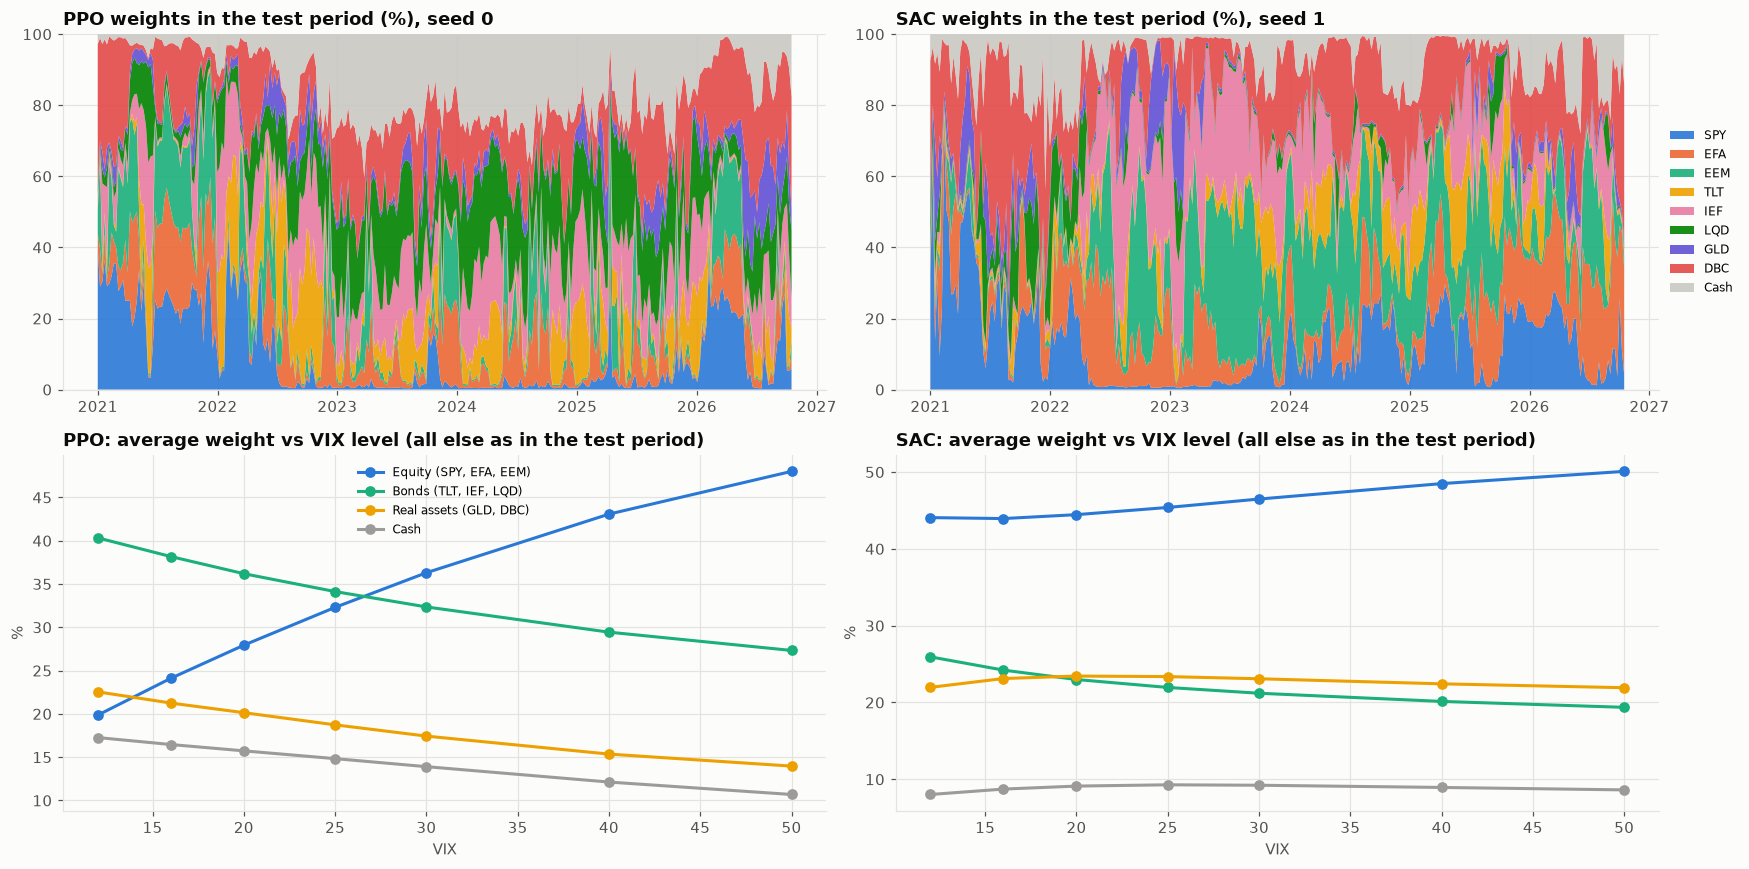

PPO                     SAC                  
        12    20    30    50    12    20    30    50
SPY   6.60  9.50 11.90 15.40 10.70 13.90 16.90 20.40
EFA   7.50  9.00 10.80 13.00 15.60 12.50 11.60 11.70
EEM   5.80  9.40 13.60 19.60 17.70 18.00 17.90 18.00
TLT  10.50  8.70  7.20  5.40  6.70  5.90  5.70  5.70
IEF  13.70 12.10 10.60  8.90 13.70 13.30 12.50 11.40
LQD  16.20 15.30 14.60 13.00  5.50  3.80  3.00  2.30
GLD   5.40  4.30  3.70  2.90  4.20  4.60  4.30  3.50
DBC  17.20 15.80 13.70 11.10 17.80 18.90 18.70 18.40
Cash 17.30 15.70 13.90 10.70  8.00  9.10  9.20  8.60

In [10]:
# --- Chart 2: weight paths and VIX response
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for k, algo in enumerate(("PPO", "SAC")):
    W = agent_runs[(algo, best_seed[algo], "test")][2]
    axes[0, k].stackplot(
        W.index,
        W.T.values * 100,
        colors=[ASSET_COLORS[a] for a in ASSETS],
        labels=ASSETS,
        alpha=0.9,
    )
    axes[0, k].set_ylim(0, 100)
    axes[0, k].set_title(
        f"{algo} weights in the test period (%), seed {best_seed[algo]}"
    )
axes[0, 1].legend(
    fontsize=8, ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5)
)

lo, hi = PERIODS["test"]
vix_col = list(Z.columns).index(("macro", "vix"))
vix_levels = np.array([12, 16, 20, 25, 30, 40, 50])
response = {}
for k, algo in enumerate(("PPO", "SAC")):
    model = agents[(algo, best_seed[algo])]
    W_test = agent_runs[(algo, best_seed[algo], "test")][2].to_numpy()
    curves = []
    for v in vix_levels:
        obs = np.concatenate(
            [Z_ALL[lo:hi], W_test.astype(np.float32)], axis=1
        ).copy()
        obs[:, vix_col] = (np.log(v) - mu_f[("macro", "vix")]) / sd_f[
            ("macro", "vix")
        ]
        a, _ = model.predict(obs, deterministic=True)
        e = np.exp(2 * a - (2 * a).max(axis=1, keepdims=True))
        curves.append((e / e.sum(axis=1, keepdims=True)).mean(axis=0))
    response[algo] = pd.DataFrame(curves, index=vix_levels, columns=ASSETS)
    groups = {
        "Equity (SPY, EFA, EEM)": ["SPY", "EFA", "EEM"],
        "Bonds (TLT, IEF, LQD)": ["TLT", "IEF", "LQD"],
        "Real assets (GLD, DBC)": ["GLD", "DBC"],
        "Cash": ["Cash"],
    }
    for (g, cols), color in zip(
        groups.items(), [PALETTE[0], PALETTE[2], PALETTE[3], "#9c9b97"]
    ):
        axes[1, k].plot(
            vix_levels,
            response[algo][cols].sum(axis=1) * 100,
            "o-",
            color=color,
            label=g,
        )
    axes[1, k].set_title(
        f"{algo}: average weight vs VIX level (all else as in the test period)"
    )
    axes[1, k].set_xlabel("VIX")
    axes[1, k].set_ylabel("%")
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_weights_and_vix_response")
plt.show()
pd.concat(
    {a: r.T.loc[:, [12, 20, 30, 50]] * 100 for a, r in response.items()},
    axis=1,
).round(1)

## 9. Results dashboard

In [11]:
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.14,
    horizontal_spacing=0.08,
    specs=[[{"colspan": 2}, None], [{}, {}]],
    subplot_titles=(
        "Growth of $1, test period 2021–2026 (net of costs)",
        "Sharpe ratio, test period",
        "Annual turnover (×), test period",
    ),
)
for n in RULES:
    r = bench[(n, "test")][0]
    dash.add_trace(
        go.Scatter(
            x=r.index,
            y=(1 + r).cumprod(),
            name=n,
            line=dict(color=STRAT_COLORS[n], width=1.6),
        ),
        1,
        1,
    )
for algo in ("PPO", "SAC"):
    r = agent_runs[(algo, best_seed[algo], "test")][0]
    dash.add_trace(
        go.Scatter(
            x=r.index,
            y=(1 + r).cumprod(),
            name=f"{algo} (seed {best_seed[algo]})",
            line=dict(color=STRAT_COLORS[algo], width=2.2),
        ),
        1,
        1,
    )
names = list(scoreboard.index)
colors = [STRAT_COLORS.get(n.split(" (")[0], "#9c9b97") for n in names]
dash.add_trace(
    go.Bar(
        x=names,
        y=scoreboard["Sharpe"],
        marker_color=colors,
        showlegend=False,
        text=scoreboard["Sharpe"].round(2),
        textposition="outside",
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=names,
        y=scoreboard["annual turnover ×"],
        marker_color=colors,
        showlegend=False,
        text=scoreboard["annual turnover ×"].round(1),
        textposition="outside",
    ),
    2,
    2,
)
top = scoreboard["Sharpe"].idxmax()
dash.update_layout(
    height=900,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=1.02, x=0.5, xanchor="center"),
    margin=dict(t=140),
    title=dict(
        x=0.01,
        text=(
            "<b>RL asset allocation · out of sample"
            f" {Z.index[PERIODS['test'][0] + 1]:%b %Y} –"
            f" {Z.index[-1]:%b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>8 ETFs + cash · weekly, 10"
            " bp costs · best Sharpe:"
            f" {top} ({scoreboard.loc[top, 'Sharpe']:.2f}) · 1/N:"
            f" {scoreboard.loc['1/N', 'Sharpe']:.2f}</span>"
        ),
    ),
)
dash.update_xaxes(tickangle=-30, row=2)
save_dashboard(dash, "dashboard")
scoreboard.to_csv(OUT_DIR / "test_scoreboard.csv")
seed_table.to_csv(OUT_DIR / "seed_results.csv")
pd.concat({a: r for a, r in response.items()}).to_csv(
    OUT_DIR / "vix_response.csv"
)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

Test period January 2021 – October 2026 (303 weeks), net of 10 bp costs:

**The agents beat the simple rules on paper, but not convincingly.** The best-validation PPO seed has a Sharpe ratio of 0.57 and the best SAC seed 0.55, against 0.42 for 1/N, 0.48 for 60/40 and 0.53 for trend following. The block bootstrap gives PPO a 70% probability of a higher Sharpe than 1/N.

That is far from significant, and about the same as minimum variance (77%), which needs no training at all.

- **Seeds matter as much as the algorithm.** The three PPO seeds are consistent (test Sharpe 0.52–0.61). The three SAC seeds range from −0.10 to 0.55, with an average of 0.24, below every benchmark. Validation-based seed selection happened to pick the good SAC seed; an unlucky choice would have deployed the loser.

**The training numbers are the red flag.** In 2008–2018 PPO earns about 45% a year with a Sharpe above 3, and SAC about 18%. No allocation rule can do that out of sample. Each week's state vector is almost unique, so a flexible policy can memorise which state preceded which return.

That is overfitting in the RL setting, and the validation and test numbers (8–13% a year) are the honest ones.

**Turnover would kill it in practice.** Both agents turn over 18–20× a year, against 0.6× for 1/N and 5× for trend following. At 10 bp this costs about 2% a year, already inside the returns above. A more realistic 20–30 bp for a mix of ETFs and futures would wipe out the advantage. A higher cost or a turnover penalty in the reward is the first thing to change.

**The learned policy is not "risk-off".** When the VIX is set higher, PPO **raises** equities from 20% to 48% and cuts bonds and cash; SAC does the same more mildly. In 2008–2018 high-VIX weeks were followed by strong rebounds (2009, 2011, 2016), so the agent learned to buy fear.

Buying fear is the opposite of what a treasury mandate would accept, and it is exactly the kind of behaviour a validator should find before deployment.

- **The simplest risk control wins on risk.** Trend following had a maximum drawdown of −6.6% and the lowest CVaR, against −16% to −21% for every other strategy. In a period with a bond crash (TLT −8% a year), the rule that moves to cash when 52-week returns turn negative did what a liquidity portfolio needs.

**Limitations**

- Eight ETFs, weekly decisions, one train/validation/test split. A rolling retraining scheme and more seeds would give a fairer picture of RL's variance.
- Hyper-parameters (network size, steps, γ, risk penalty) are fixed, not tuned, so the agents are not at their best; tuning them on the validation period would add a further layer of selection bias.
- No market impact, borrowing or short positions. The reward is a mean–variance proxy, not the drawdown or CVaR constraints a real mandate would impose.

## References

### Finance and regulation

- DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal versus naive diversification: How inefficient is the 1/N portfolio strategy? *The Review of Financial Studies, 22*(5), 1915–1953. https://doi.org/10.1093/rfs/hhm075
- Moskowitz, T. J., Ooi, Y. H., & Pedersen, L. H. (2012). Time series momentum. *Journal of Financial Economics, 104*(2), 228–250. https://doi.org/10.1016/j.jfineco.2011.11.003
- Ledoit, O., & Wolf, M. (2008). Robust performance hypothesis testing with the Sharpe ratio. *Journal of Empirical Finance, 15*(5), 850–859. https://doi.org/10.1016/j.jempfin.2008.03.002
- Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association, 89*(428), 1303–1313. https://doi.org/10.1080/01621459.1994.10476870

### Machine learning and deep learning

- Schulman, J., Wolski, F., Dhariwal, P., Radford, A., & Klimov, O. (2017). Proximal policy optimization algorithms. *arXiv*. https://arxiv.org/abs/1707.06347
- Haarnoja, T., Zhou, A., Abbeel, P., & Levine, S. (2018). Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor. In *Proceedings of the 35th International Conference on Machine Learning*. https://arxiv.org/abs/1801.01290
- Raffin, A., Hill, A., Gleave, A., Kanervisto, A., Ernestus, M., & Dormann, N. (2021). Stable-Baselines3: Reliable reinforcement learning implementations. *Journal of Machine Learning Research, 22*(268), 1–8. https://jmlr.org/papers/v22/20-1364.html
- Henderson, P., Islam, R., Bachman, P., Pineau, J., Precup, D., & Meger, D. (2018). Deep reinforcement learning that matters. In *Proceedings of the AAAI Conference on Artificial Intelligence, 32*. https://arxiv.org/abs/1709.06560
- Hambly, B., Xu, R., & Yang, H. (2023). Recent advances in reinforcement learning in finance. *Mathematical Finance, 33*(3), 437–503. https://doi.org/10.1111/mafi.12382